# Primera Version Completa del GA con Evaluacion Paralela Real

**Objetivo (Hito 6):** Integrar en un unico notebook el ciclo evolutivo completo del Algoritmo Genetico (seleccion, cruce, mutacion, elitismo) con la evaluacion paralela real de fitness usando Gaussian Naive Bayes (GNB) y validacion cruzada de 5 pliegues sobre Spark RDD.

**Observaciones a recoger:**
1. **Convergencia**: evolucion del mejor fitness generacion tras generacion.
2. **Evolucion del fitness**: mejor, medio y peor por generacion.
3. **Numero de caracteristicas seleccionadas**: presion selectiva hacia subconjuntos parsimoniosos.
4. **Tiempos**: duracion de la fase de evaluacion (Workers) vs. operadores geneticos (Driver) por generacion.

**Coherencia con el diseno del TFM:**
- Parametros del GA: tomados de la tabla de `diseño_GA.md` §6 (columna WDBC).
- Clasificador: GNB por su velocidad y ausencia de hiperparametros (§5.1).
- Patron de paralelizacion: `sc.parallelize -> map -> collect` con broadcast del dataset, segun `arquitectura_spark_rdd_ga.md` §2.
- Criterio de parada dual: $G_{max}$ generaciones **o** $\Delta\text{fitness} < 0.001$ en las ultimas $N_{stop}=10$ generaciones.

**Cobertura tambien del Hito 7** (documentacion): la seccion final captura configuracion de Spark, hardware y parametros del GA en un bloque reproducible, y exporta todas las series temporales a CSV.

---
## 1. Setup: Spark Session e Imports

In [1]:
import sys
sys.path.insert(0, '../src')

from spark_config import crear_sesion_spark, mostrar_info_spark, parar_spark
import numpy as np
import time
from datetime import datetime
from sklearn.datasets import load_breast_cancer
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_val_score

print(f"Notebook iniciado: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

Notebook iniciado: 2026-04-17 11:30:38


In [2]:
SPARK_APP_NAME = "TFM_GA_Full_Version"
SPARK_MASTER = "local[*]"
SPARK_DRIVER_MEM = "4g"
SPARK_EXECUTOR_MEM = "4g"
SPARK_UI_PORT = 4040

spark = crear_sesion_spark(
    app_name=SPARK_APP_NAME,
    master=SPARK_MASTER,
    driver_memory=SPARK_DRIVER_MEM,
    executor_memory=SPARK_EXECUTOR_MEM,
    ui_port=SPARK_UI_PORT,
    verbose=False
)

sc = spark.sparkContext
mostrar_info_spark(spark, ui_port=SPARK_UI_PORT)

NUM_CORES = sc.defaultParallelism
print(f"\nCores disponibles para paralelismo: {NUM_CORES}")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/04/17 11:30:39 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


🔥 INFORMACIÓN DE SPARK SESSION
✓ App Name: TFM_GA_Full_Version
✓ Master: local[*]
✓ Spark Version: 3.5.0
✓ Python Version: 3.9
✓ Default Parallelism: 4
✓ Default Min Partitions: 2

🌐 SPARK WEB UI
📊 Accede en tu navegador a:
   👉 http://localhost:4040

   Opciones disponibles:
   - Jobs: Ver trabajos en ejecución/completados
   - Stages: Ver stages de cada job
   - Storage: Ver RDDs cacheados
   - Environment: Configuración de Spark
   - Executors: Estado de ejecutores


Cores disponibles para paralelismo: 4


26/04/17 11:30:39 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.
26/04/17 11:30:39 WARN Utils: Service 'SparkUI' could not bind on port 4041. Attempting port 4042.


---
## 2. Carga del Dataset WDBC (Wisconsin Diagnostic Breast Cancer)

El dataset tiene 30 caracteristicas numericas y una variable objetivo binaria (maligno/benigno). Las 30 caracteristicas corresponden exactamente a la longitud del cromosoma $D = 30$.

In [3]:
# Cargar dataset
dataset = load_breast_cancer()
X = dataset.data    # (569, 30)
y = dataset.target  # 0=maligno, 1=benigno
D = X.shape[1]      # 30 caracteristicas
feature_names = dataset.feature_names

print(f"Dataset: {dataset.DESCR.splitlines()[0]}")
print(f"Muestras: {X.shape[0]}")
print(f"Caracteristicas (D): {D}")
print(f"Clases: {dict(zip(dataset.target_names, np.bincount(y)))}")
print(f"\nPrimeras 5 caracteristicas: {list(feature_names[:5])}")

Dataset: .. _breast_cancer_dataset:
Muestras: 569
Caracteristicas (D): 30
Clases: {'malignant': 212, 'benign': 357}

Primeras 5 caracteristicas: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness']


---
## 3. Configuracion del GA (Hiperparametros)

Parametros tomados de `diseño_GA.md` §6 (columna WDBC). Se agrupan aqui en un unico bloque para facilitar reproducibilidad y la exportacion en el resumen del Hito 7.

| Parametro | Simbolo | Valor | Justificacion |
|---|---|---|---|
| Tamano poblacion | $P$ | 50 | Compromiso entre diversidad y coste |
| Max generaciones | $G_{max}$ | 50 | Suficiente para convergencia en WDBC |
| Prob. cruce | $p_{cross}$ | 0.8 | Estandar en literatura GA |
| Prob. mutacion individuo | $p_{mut}$ | 0.2 | Mantiene diversidad |
| Prob. flip por gen | $p_{mut\_bit}$ | $1/D$ | ~1 bit por cromosoma en media |
| Tamano torneo | $k$ | 5 | Presion selectiva moderada |
| Elitismo | $E$ | 2 | Preserva los mejores |
| Prob. init. gen | $p_{init}$ | 0.5 | Poblacion inicial equiprobable |
| Tolerancia parada | $\varepsilon_{stop}$ | 0.001 | Δfitness para considerar estancamiento |
| Ventana parada | $N_{stop}$ | 10 | Generaciones sin mejora significativa |
| Peso accuracy | $\alpha$ | 0.9 | Peso principal del fitness |
| Peso parsimonia | $\beta$ | 0.1 | Penalizacion al num. de caracteristicas |

In [4]:
# ==== Hiperparametros del GA (diseño_GA.md §6, columna WDBC) ====
# Poblacion y evolucion
P          = 50           # Tamano de la poblacion
G_MAX      = 50           # Maximo numero de generaciones
P_INIT     = 0.5          # Probabilidad de inicializacion de cada gen

# Operadores geneticos
P_CROSS    = 0.8          # Probabilidad de cruce
P_MUT      = 0.2          # Probabilidad de mutacion de individuo
P_MUT_BIT  = 1.0 / D      # Probabilidad de flip por gen (~1/D)
K_TOURN    = 5            # Tamano del torneo
ELITE_SIZE = 2            # Numero de individuos preservados por elitismo

# Criterio de parada dual
EPS_STOP   = 0.001        # Delta-fitness minimo para considerar mejora
N_STOP     = 10           # Ventana (generaciones) sin mejora significativa

# Funcion fitness
ALPHA      = 0.9          # Peso de la accuracy
BETA       = 0.1          # Peso de la penalizacion por num. caracteristicas
CV_FOLDS   = 5            # Folds de validacion cruzada

# Semillas (reproducibilidad)
SEED = 42
np.random.seed(SEED)

# ==== Poblacion inicial ====
poblacion_inicial = [list(np.random.binomial(1, P_INIT, D)) for _ in range(P)]

print("Configuracion del GA:")
print(f"  P={P}, G_max={G_MAX}, D={D}")
print(f"  p_cross={P_CROSS}, p_mut={P_MUT}, p_mut_bit={P_MUT_BIT:.4f}")
print(f"  k_tourn={K_TOURN}, elite={ELITE_SIZE}, p_init={P_INIT}")
print(f"  Parada: G_max={G_MAX} o Δfitness<{EPS_STOP} en {N_STOP} gens")
print(f"  Fitness: alpha={ALPHA}, beta={BETA}, cv={CV_FOLDS}")
print(f"\nPoblacion inicial: {P} individuos, cromosoma de longitud {D}")
print(f"  Genes activos en individuo[0]: {sum(poblacion_inicial[0])}/{D}")

Configuracion del GA:
  P=50, G_max=50, D=30
  p_cross=0.8, p_mut=0.2, p_mut_bit=0.0333
  k_tourn=5, elite=2, p_init=0.5
  Parada: G_max=50 o Δfitness<0.001 en 10 gens
  Fitness: alpha=0.9, beta=0.1, cv=5

Poblacion inicial: 50 individuos, cromosoma de longitud 30
  Genes activos en individuo[0]: 13/30


---
## 4. Funcion Fitness con Gaussian Naive Bayes (Paralela con Spark)

La funcion fitness entrena un clasificador **Gaussian Naive Bayes** usando unicamente las caracteristicas activas (genes = 1) del cromosoma, y evalua su rendimiento con **validacion cruzada de 5 pliegues**.

$$F(\mathbf{c}) = \alpha \cdot \text{Accuracy}_{CV5}(\mathbf{c}) - \beta \cdot \frac{|S|}{D}$$

Donde $|S|$ es el numero de caracteristicas seleccionadas y $D$ el total. $\alpha=0.9$ pondera el acierto; $\beta=0.1$ penaliza subconjuntos grandes.

Para la evaluacion paralela los datos `X` e `y` se envian como variables broadcast, evitando copias redundantes a los workers. Este patron (`sc.parallelize -> map -> collect`) sigue lo descrito en `arquitectura_spark_rdd_ga.md` §2.

> La correctitud de esta evaluacion paralela (resultados identicos a ejecucion secuencial) y el speed-up asociado ya fueron validados en los notebooks `02_gnb_fitness_evaluation.ipynb` (Hito 4) y `03_speedup_experiment.ipynb` (Hito 5). Aqui pasamos directamente a integrarla en el ciclo evolutivo.

In [5]:
# Broadcast de los datos a los workers
X_bc = sc.broadcast(X)
y_bc = sc.broadcast(y)


def evaluar_fitness(cromosoma):
    """Evalua el fitness de un cromosoma usando GNB con validacion cruzada.

    1. Selecciona las columnas de X correspondientes a genes activos (=1)
    2. Entrena GaussianNB con 5-fold cross-validation
    3. Calcula: fitness = alpha * accuracy_media - beta * (n_activos / D)

    Si el cromosoma no tiene genes activos, retorna 0.0.
    """
    indices_activos = [i for i, gen in enumerate(cromosoma) if gen == 1]
    d = len(cromosoma)

    if len(indices_activos) == 0:
        return 0.0

    X_data = X_bc.value[:, indices_activos]
    y_data = y_bc.value

    gnb = GaussianNB()
    scores = cross_val_score(gnb, X_data, y_data, cv=CV_FOLDS, scoring='accuracy')
    accuracy = scores.mean()

    penalizacion = len(indices_activos) / d
    return round(ALPHA * accuracy - BETA * penalizacion, 6)


def evaluar_poblacion_paralela(pop):
    """Evalua toda la poblacion en paralelo con Spark RDD.

    Retorna la lista de fitness (mismo orden que pop).
    """
    rdd = sc.parallelize(pop, numSlices=NUM_CORES)
    return rdd.map(evaluar_fitness).collect()


# Test rapido con un individuo del la poblacion inicial
test_cromosoma = poblacion_inicial[0]
test_fitness = evaluar_fitness(test_cromosoma)
print(f"Test fitness individuo[0]: {test_fitness:.6f}")
print(f"  Genes activos: {sum(test_cromosoma)}/{D}")
print(f"  Broadcast X shape: {X_bc.value.shape}")
print(f"  Broadcast y shape: {y_bc.value.shape}")

Test fitness individuo[0]: 0.798134
  Genes activos: 13/30
  Broadcast X shape: (569, 30)
  Broadcast y shape: (569,)


---
## 5. Operadores Geneticos

Implementamos los operadores descritos en `diseño_GA.md` §3 de forma modular, siguiendo el esquema **toolbox** de estilo DEAP (aunque DEAP no esta instalado en el entorno y por tanto se definen manualmente con `random`):

- `seleccion_torneo(pop, fit, k)`: torneo de tamano $k$ (presion selectiva moderada).
- `cruce_un_punto(p1, p2)`: corte en un punto aleatorio.
- `mutacion_flip(ind, p_mut_bit)`: bit-flip gen a gen.
- `elitismo(pop, fit, e)`: conserva los $e$ mejores sin modificar.
- `siguiente_generacion(pop, fit)`: aplica elitismo + torneo + cruce + mutacion hasta reconstituir una poblacion de tamano $P$.

> **Nota tecnica:** se dejo como tarea pendiente la integracion con DEAP; cuando se disponga de la libreria, estos operadores manuales pueden sustituirse por `toolbox.register(...)` manteniendo las mismas signaturas.

In [6]:
import random
random.seed(SEED)


def seleccion_torneo(pop, fit, k=K_TOURN):
    """Torneo de tamano k: elige k individuos al azar y devuelve el mejor."""
    candidatos = random.sample(range(len(pop)), k)
    ganador = max(candidatos, key=lambda i: fit[i])
    return list(pop[ganador])


def cruce_un_punto(p1, p2):
    """Cruce de un punto: intercambia colas a partir de un punto aleatorio."""
    punto = random.randint(1, len(p1) - 1)
    h1 = p1[:punto] + p2[punto:]
    h2 = p2[:punto] + p1[punto:]
    return h1, h2


def mutacion_flip(ind, p_mut_bit=P_MUT_BIT):
    """Mutacion bit-flip: invierte cada gen con probabilidad p_mut_bit."""
    return [1 - g if random.random() < p_mut_bit else g for g in ind]


def elitismo(pop, fit, e=ELITE_SIZE):
    """Devuelve copias de los e mejores individuos de la poblacion."""
    idx = sorted(range(len(fit)), key=lambda i: fit[i], reverse=True)[:e]
    return [list(pop[i]) for i in idx]


def siguiente_generacion(pop, fit):
    """Construye la siguiente generacion: elitismo + torneo + cruce + mutacion."""
    nueva = elitismo(pop, fit, ELITE_SIZE)
    while len(nueva) < P:
        p1 = seleccion_torneo(pop, fit, K_TOURN)
        p2 = seleccion_torneo(pop, fit, K_TOURN)
        if random.random() < P_CROSS:
            h1, h2 = cruce_un_punto(p1, p2)
        else:
            h1, h2 = list(p1), list(p2)
        if random.random() < P_MUT:
            h1 = mutacion_flip(h1)
        if random.random() < P_MUT:
            h2 = mutacion_flip(h2)
        nueva.append(h1)
        if len(nueva) < P:
            nueva.append(h2)
    return nueva


print("Operadores geneticos definidos (estilo DEAP toolbox, manual):")
print(f"  seleccion_torneo(k={K_TOURN})")
print(f"  cruce_un_punto (p_cross={P_CROSS})")
print(f"  mutacion_flip (p_mut={P_MUT}, p_mut_bit={P_MUT_BIT:.4f})")
print(f"  elitismo (e={ELITE_SIZE})")

Operadores geneticos definidos (estilo DEAP toolbox, manual):
  seleccion_torneo(k=5)
  cruce_un_punto (p_cross=0.8)
  mutacion_flip (p_mut=0.2, p_mut_bit=0.0333)
  elitismo (e=2)


---
## 6. Ciclo Evolutivo con Criterio de Parada Dual

El bucle principal del GA integra todos los componentes anteriores:

1. **Evaluacion paralela** con Spark (Workers, tiempo $t_{eval}$).
2. **Registro de metricas** (mejor/medio/peor, caracteristicas, tiempos).
3. **Test de parada temprana**: se detiene si en las ultimas $N_{stop}=10$ generaciones el mejor fitness no ha mejorado al menos $\varepsilon_{stop}=0.001$.
4. **Operadores geneticos** (Driver, tiempo $t_{ops}$) para construir la siguiente generacion.

Se mide por separado el tiempo de evaluacion (Workers) y el tiempo de operadores (Driver) para poder analizar el reparto de costes.

In [7]:
print(f"Ejecutando GA completo: P={P}, G_max={G_MAX}, D={D}")
print(f"Parada dual: G_max={G_MAX}  o  Δfitness<{EPS_STOP} en ultimas {N_STOP} gens")
print(f"Clasificador=GNB, CV={CV_FOLDS}-fold, alpha={ALPHA}, beta={BETA}")
print(f">>> Observa los jobs en http://localhost:{SPARK_UI_PORT} <<<\n")

pop = [list(ind) for ind in poblacion_inicial]

# Historicos
hist_mejor = []
hist_medio = []
hist_peor  = []
hist_genes = []
t_eval_gen = []   # Tiempo Spark (Workers)
t_ops_gen  = []   # Tiempo operadores (Driver)

mejor_global = None
mejor_fitness_global = -1.0

gen_parada = None
motivo_parada = None

t_total_ini = time.time()

for gen in range(1, G_MAX + 1):
    # --- Evaluacion paralela (Workers) ---
    t0 = time.time()
    scores = evaluar_poblacion_paralela(pop)
    t_eval = time.time() - t0
    t_eval_gen.append(t_eval)

    # --- Metricas ---
    mejor = max(scores)
    medio = float(np.mean(scores))
    peor  = min(scores)
    genes_medio = float(np.mean([sum(ind) for ind in pop]))
    hist_mejor.append(mejor)
    hist_medio.append(medio)
    hist_peor.append(peor)
    hist_genes.append(genes_medio)

    # Guardar mejor individuo global
    idx = scores.index(mejor)
    if mejor > mejor_fitness_global:
        mejor_fitness_global = mejor
        mejor_global = list(pop[idx])

    # --- Test de parada dual ---
    if gen >= N_STOP:
        ventana = hist_mejor[-N_STOP:]
        delta = max(ventana) - min(ventana)
        if delta < EPS_STOP:
            gen_parada = gen
            motivo_parada = f"convergencia (Δ={delta:.6f} < {EPS_STOP} en {N_STOP} gens)"
            # Operadores no se ejecutan en la ultima generacion (no habra siguiente)
            t_ops_gen.append(0.0)
            print(f"  Gen {gen:>3d}/{G_MAX} | Mejor={mejor:.6f} | Media={medio:.6f} | "
                  f"Genes={genes_medio:4.1f} | t_eval={t_eval:.2f}s  [PARADA]")
            break

    # --- Operadores geneticos (Driver) ---
    t0 = time.time()
    pop = siguiente_generacion(pop, scores)
    t_ops = time.time() - t0
    t_ops_gen.append(t_ops)

    print(f"  Gen {gen:>3d}/{G_MAX} | Mejor={mejor:.6f} | Media={medio:.6f} | "
          f"Genes={genes_medio:4.1f} | t_eval={t_eval:.2f}s | t_ops={t_ops:.3f}s")

t_total = time.time() - t_total_ini

if gen_parada is None:
    gen_parada = G_MAX
    motivo_parada = f"G_max alcanzado ({G_MAX} generaciones)"

print(f"\n{'=' * 64}")
print(f"GA completado: {gen_parada} generaciones")
print(f"Motivo de parada: {motivo_parada}")
print(f"Tiempo total: {t_total:.2f}s")
print(f"  Tiempo evaluacion (Workers): {sum(t_eval_gen):.2f}s ({sum(t_eval_gen)/t_total*100:.1f}%)")
print(f"  Tiempo operadores (Driver):  {sum(t_ops_gen):.2f}s ({sum(t_ops_gen)/t_total*100:.1f}%)")
print(f"Tiempo medio por generacion: {t_total/gen_parada:.2f}s")
print(f"\nMejor fitness global: {mejor_fitness_global:.6f}")
print(f"Genes activos del mejor: {sum(mejor_global)}/{D}")
print('=' * 64)

Ejecutando GA completo: P=50, G_max=50, D=30
Parada dual: G_max=50  o  Δfitness<0.001 en ultimas 10 gens
Clasificador=GNB, CV=5-fold, alpha=0.9, beta=0.1
>>> Observa los jobs en http://localhost:4040 <<<



  Gen   1/50 | Mejor=0.815909 | Media=0.788841 | Genes=15.2 | t_eval=1.03s | t_ops=0.000s
  Gen   2/50 | Mejor=0.815909 | Media=0.802238 | Genes=12.9 | t_eval=0.07s | t_ops=0.000s
  Gen   3/50 | Mejor=0.825734 | Media=0.808448 | Genes=11.9 | t_eval=0.06s | t_ops=0.000s
  Gen   4/50 | Mejor=0.833642 | Media=0.819790 | Genes=10.7 | t_eval=0.06s | t_ops=0.000s
  Gen   5/50 | Mejor=0.841537 | Media=0.826136 | Genes=10.0 | t_eval=0.06s | t_ops=0.000s
  Gen   6/50 | Mejor=0.841537 | Media=0.830006 | Genes= 9.4 | t_eval=0.06s | t_ops=0.000s
  Gen   7/50 | Mejor=0.841698 | Media=0.834416 | Genes= 9.1 | t_eval=0.06s | t_ops=0.000s
  Gen   8/50 | Mejor=0.848028 | Media=0.837026 | Genes= 8.8 | t_eval=0.06s | t_ops=0.001s
  Gen   9/50 | Mejor=0.848028 | Media=0.841589 | Genes= 8.7 | t_eval=0.07s | t_ops=0.000s
  Gen  10/50 | Mejor=0.848028 | Media=0.843688 | Genes= 8.2 | t_eval=0.07s | t_ops=0.000s
  Gen  11/50 | Mejor=0.848028 | Media=0.845994 | Genes= 8.1 | t_eval=0.07s | t_ops=0.000s
  Gen  12/

---
## 7. Visualizacion: Convergencia y Evolucion

Cuatro graficos que muestran:
1. **Convergencia del mejor fitness** (acumulado) — cuan rapido el GA alcanza su mejor valor.
2. **Evolucion de fitness** (mejor / medio / peor por generacion).
3. **Numero medio de caracteristicas** seleccionadas por generacion.
4. **Reparto de tiempos** por generacion (Workers vs Driver).

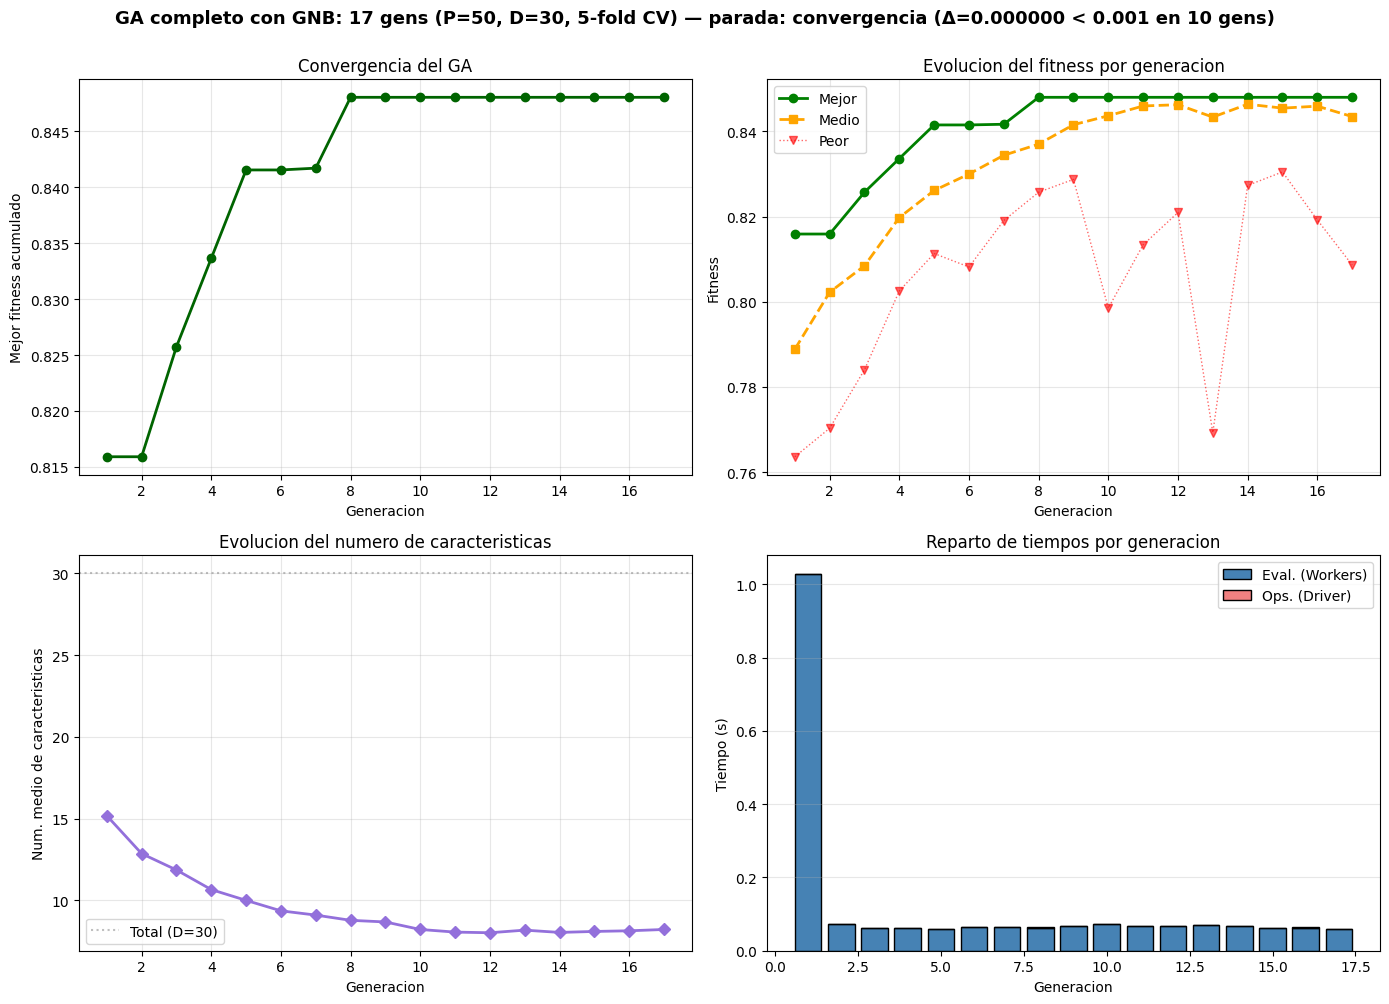

Grafico guardado en results/ga_full_convergencia.png


In [8]:
import matplotlib.pyplot as plt

gens = list(range(1, gen_parada + 1))

# Mejor fitness acumulado (monotonamente creciente)
mejor_acum = []
actual = -float('inf')
for v in hist_mejor:
    actual = max(actual, v)
    mejor_acum.append(actual)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (1) Convergencia: mejor fitness acumulado
axes[0, 0].plot(gens, mejor_acum, 'o-', color='darkgreen', linewidth=2)
axes[0, 0].set_xlabel('Generacion')
axes[0, 0].set_ylabel('Mejor fitness acumulado')
axes[0, 0].set_title('Convergencia del GA')
axes[0, 0].grid(True, alpha=0.3)

# (2) Evolucion del fitness (mejor / medio / peor)
axes[0, 1].plot(gens, hist_mejor, 'o-', color='green', linewidth=2, label='Mejor')
axes[0, 1].plot(gens, hist_medio, 's--', color='orange', linewidth=2, label='Medio')
axes[0, 1].plot(gens, hist_peor,  'v:', color='red', linewidth=1, alpha=0.6, label='Peor')
axes[0, 1].set_xlabel('Generacion')
axes[0, 1].set_ylabel('Fitness')
axes[0, 1].set_title('Evolucion del fitness por generacion')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# (3) Num. medio de caracteristicas
axes[1, 0].plot(gens, hist_genes, 'D-', color='mediumpurple', linewidth=2)
axes[1, 0].axhline(y=D, color='gray', linestyle=':', alpha=0.5, label=f'Total (D={D})')
axes[1, 0].set_xlabel('Generacion')
axes[1, 0].set_ylabel('Num. medio de caracteristicas')
axes[1, 0].set_title('Evolucion del numero de caracteristicas')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# (4) Reparto de tiempos: evaluacion (Workers) vs operadores (Driver)
width = 0.8
axes[1, 1].bar(gens, t_eval_gen, width=width, color='steelblue',
               edgecolor='black', label='Eval. (Workers)')
axes[1, 1].bar(gens, t_ops_gen,  width=width, bottom=t_eval_gen,
               color='lightcoral', edgecolor='black', label='Ops. (Driver)')
axes[1, 1].set_xlabel('Generacion')
axes[1, 1].set_ylabel('Tiempo (s)')
axes[1, 1].set_title('Reparto de tiempos por generacion')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3, axis='y')

plt.suptitle(
    f'GA completo con GNB: {gen_parada} gens (P={P}, D={D}, {CV_FOLDS}-fold CV) — '
    f'parada: {motivo_parada}',
    fontsize=13, fontweight='bold', y=1.0
)
plt.tight_layout()
plt.savefig('../results/ga_full_convergencia.png', dpi=150, bbox_inches='tight')
plt.show()
print("Grafico guardado en results/ga_full_convergencia.png")

---
## 8. Mejor Individuo Encontrado y Comparacion con Baseline

In [9]:
# Analisis del mejor individuo encontrado
indices_mejor = [i for i, gen in enumerate(mejor_global) if gen == 1]
nombres_mejor = feature_names[indices_mejor]

# Recalcular accuracy del mejor individuo (sin penalizacion)
gnb_final = GaussianNB()
scores_final = cross_val_score(gnb_final, X[:, indices_mejor], y, cv=CV_FOLDS, scoring='accuracy')

print("=" * 60)
print("MEJOR INDIVIDUO ENCONTRADO")
print("=" * 60)
print(f"Fitness:  {mejor_fitness_global:.6f}")
print(f"Accuracy (CV5): {scores_final.mean():.6f} (+/- {scores_final.std():.6f})")
print(f"Caracteristicas: {len(indices_mejor)}/{D} ({len(indices_mejor)/D*100:.0f}%)")
print(f"\nCaracteristicas seleccionadas:")
for i, nombre in enumerate(nombres_mejor):
    print(f"  {i+1:>2d}. {nombre}")

print(f"\n{'=' * 60}")
print(f"COMPARACION CON BASELINE (todas las caracteristicas)")
print(f"{'=' * 60}")
gnb_base = GaussianNB()
scores_base = cross_val_score(gnb_base, X, y, cv=CV_FOLDS, scoring='accuracy')
fitness_base = ALPHA * scores_base.mean() - BETA * 1.0

print(f"Baseline accuracy (CV5): {scores_base.mean():.6f} (+/- {scores_base.std():.6f})")
print(f"Baseline fitness:        {fitness_base:.6f}")
print(f"Mejor GA fitness:        {mejor_fitness_global:.6f}")
print(f"Mejora en fitness:       {mejor_fitness_global - fitness_base:+.6f}")
print(f"Reduccion caracteristicas: {D} -> {len(indices_mejor)} ({(1 - len(indices_mejor)/D)*100:.0f}% menos)")
print("=" * 60)

MEJOR INDIVIDUO ENCONTRADO
Fitness:  0.848028
Accuracy (CV5): 0.971883 (+/- 0.003487)
Caracteristicas: 8/30 (27%)

Caracteristicas seleccionadas:
   1. mean texture
   2. mean symmetry
   3. area error
   4. concavity error
   5. worst radius
   6. worst texture
   7. worst smoothness
   8. worst concave points

COMPARACION CON BASELINE (todas las caracteristicas)
Baseline accuracy (CV5): 0.938519 (+/- 0.014586)
Baseline fitness:        0.744667
Mejor GA fitness:        0.848028
Mejora en fitness:       +0.103361
Reduccion caracteristicas: 30 -> 8 (73% menos)


---
## 9. Documentacion del Experimento (Hito 7)

Captura reproducible de la configuracion del experimento para el capitulo de evaluacion experimental del TFM:

- **Configuracion de Spark** (master, cores, memoria, version)
- **Hardware** (OS, arquitectura, CPUs, versiones de librerias)
- **Parametros del GA** (tabla completa)
- **Resultados agregados** del run actual

Al final se exportan las series temporales del GA (fitness, caracteristicas, tiempos) a CSV y un JSON con el resumen del experimento — estos artefactos pueden reutilizarse directamente en el TFM.

In [10]:
import platform
import json
import os
import csv
import sklearn
import pyspark

# --- Hardware ---
hw_info = {
    "os": platform.platform(),
    "machine": platform.machine(),
    "processor": platform.processor() or "apple silicon",
    "python_version": platform.python_version(),
    "cpu_count_logical": os.cpu_count(),
}

# --- Librerias ---
lib_info = {
    "numpy": np.__version__,
    "scikit-learn": sklearn.__version__,
    "pyspark": pyspark.__version__,
    "matplotlib": plt.matplotlib.__version__,
}

# --- Spark ---
spark_info = {
    "app_name": SPARK_APP_NAME,
    "master": SPARK_MASTER,
    "driver_memory": SPARK_DRIVER_MEM,
    "executor_memory": SPARK_EXECUTOR_MEM,
    "ui_port": SPARK_UI_PORT,
    "default_parallelism": NUM_CORES,
    "spark_version": spark.version,
    "app_id": sc.applicationId,
}

# --- Parametros del GA ---
ga_params = {
    "P": P, "G_max": G_MAX, "D": D,
    "p_cross": P_CROSS, "p_mut": P_MUT, "p_mut_bit": P_MUT_BIT,
    "k_tourn": K_TOURN, "elite_size": ELITE_SIZE, "p_init": P_INIT,
    "eps_stop": EPS_STOP, "N_stop": N_STOP,
    "alpha": ALPHA, "beta": BETA, "cv_folds": CV_FOLDS,
    "seed": SEED,
}

# --- Resultados ---
# Convertimos los genes a int nativo (pueden venir como numpy.int64
# desde np.random.binomial) para que sean JSON-serializables.
mejor_cromosoma_py = [int(g) for g in mejor_global]

resultados = {
    "generaciones_ejecutadas": int(gen_parada),
    "motivo_parada": motivo_parada,
    "mejor_fitness": float(mejor_fitness_global),
    "mejor_n_caracteristicas": int(sum(mejor_cromosoma_py)),
    "mejor_cromosoma": mejor_cromosoma_py,
    "tiempo_total_s": round(float(t_total), 3),
    "tiempo_eval_total_s": round(float(sum(t_eval_gen)), 3),
    "tiempo_ops_total_s": round(float(sum(t_ops_gen)), 3),
    "tiempo_medio_gen_s": round(float(t_total) / int(gen_parada), 3),
}

print("=" * 64)
print("DOCUMENTACION DEL EXPERIMENTO (Hito 7)")
print("=" * 64)
print("\n--- Hardware ---")
for k, v in hw_info.items():
    print(f"  {k}: {v}")
print("\n--- Librerias ---")
for k, v in lib_info.items():
    print(f"  {k}: {v}")
print("\n--- Spark ---")
for k, v in spark_info.items():
    print(f"  {k}: {v}")
print("\n--- Parametros del GA ---")
for k, v in ga_params.items():
    print(f"  {k}: {v}")
print("\n--- Resultados ---")
for k, v in resultados.items():
    if k == "mejor_cromosoma":
        continue
    print(f"  {k}: {v}")
print("=" * 64)

DOCUMENTACION DEL EXPERIMENTO (Hito 7)

--- Hardware ---
  os: macOS-26.3.1-arm64-arm-64bit
  machine: arm64
  processor: arm
  python_version: 3.9.6
  cpu_count_logical: 10

--- Librerias ---
  numpy: 1.24.3
  scikit-learn: 1.3.0
  pyspark: 3.5.0
  matplotlib: 3.7.1

--- Spark ---
  app_name: TFM_GA_Full_Version
  master: local[*]
  driver_memory: 4g
  executor_memory: 4g
  ui_port: 4040
  default_parallelism: 4
  spark_version: 3.5.0
  app_id: local-1776421839484

--- Parametros del GA ---
  P: 50
  G_max: 50
  D: 30
  p_cross: 0.8
  p_mut: 0.2
  p_mut_bit: 0.03333333333333333
  k_tourn: 5
  elite_size: 2
  p_init: 0.5
  eps_stop: 0.001
  N_stop: 10
  alpha: 0.9
  beta: 0.1
  cv_folds: 5
  seed: 42

--- Resultados ---
  generaciones_ejecutadas: 17
  motivo_parada: convergencia (Δ=0.000000 < 0.001 en 10 gens)
  mejor_fitness: 0.848028
  mejor_n_caracteristicas: 8
  tiempo_total_s: 2.078
  tiempo_eval_total_s: 2.068
  tiempo_ops_total_s: 0.006
  tiempo_medio_gen_s: 0.122


In [11]:
# Exportacion de artefactos para el capitulo experimental del TFM
os.makedirs("../results", exist_ok=True)

# 1) Series temporales del GA -> CSV
csv_path = "../results/ga_full_series.csv"
with open(csv_path, "w", newline="") as f:
    w = csv.writer(f)
    w.writerow([
        "generacion", "mejor_fitness", "fitness_medio", "peor_fitness",
        "genes_medio", "t_eval_s", "t_ops_s"
    ])
    for i in range(gen_parada):
        w.writerow([
            i + 1,
            hist_mejor[i], hist_medio[i], hist_peor[i],
            hist_genes[i],
            t_eval_gen[i] if i < len(t_eval_gen) else 0.0,
            t_ops_gen[i]  if i < len(t_ops_gen)  else 0.0,
        ])
print(f"Series CSV: {csv_path}")

# 2) Resumen completo del experimento -> JSON
json_path = "../results/ga_full_experimento.json"
experimento = {
    "fecha": datetime.now().isoformat(timespec="seconds"),
    "notebook": "04_ga_full_version.ipynb",
    "hito": "Hito 6 + Hito 7",
    "hardware": hw_info,
    "librerias": lib_info,
    "spark": spark_info,
    "ga_params": ga_params,
    "resultados": resultados,
}
with open(json_path, "w") as f:
    json.dump(experimento, f, indent=2, ensure_ascii=False)
print(f"Resumen JSON: {json_path}")

# 3) Parametros del GA -> CSV (tabla reutilizable en el TFM)
params_csv = "../results/ga_full_parametros.csv"
with open(params_csv, "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["parametro", "valor"])
    for k, v in ga_params.items():
        w.writerow([k, v])
print(f"Parametros CSV: {params_csv}")

print("\nArtefactos exportados correctamente para el capitulo experimental del TFM.")

Series CSV: ../results/ga_full_series.csv
Resumen JSON: ../results/ga_full_experimento.json
Parametros CSV: ../results/ga_full_parametros.csv

Artefactos exportados correctamente para el capitulo experimental del TFM.


---
## 10. Limpieza de recursos

In [12]:
X_bc.destroy()
y_bc.destroy()
parar_spark(spark)

✓ Spark session detenida
